<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/notebooks/G03_U7_unsupervised_rl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 7 — Unsupervised and reinforcement learning**  
**Owner:** Brayson Imbambi (COM/0060/23)  
**Module:** 8  
**Loads:** data/stage1_crops.csv from Task 2.1

In [ ]:
# Mount Google Drive so we can load the cleaned data and save outputs
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Define project folder paths to keep later code short
BASE = "/content/drive/MyDrive/CSC4110_G03"
DATA = f"{BASE}/data"
OUT  = f"{BASE}/outputs"
print(BASE)

/content/drive/MyDrive/CSC4110_G03


# Part A — Clustering countries by weather and pesticide use



## (a) k-means — elbow curve and silhouette scores

In [ ]:
# Load the cleaned dataset and aggregate to ONE row per country
import pandas as pd, numpy as np
df = pd.read_csv(f"{DATA}/stage1_crops.csv")

# Average rain, temperature and pesticides per country (no targets used)
country = df.groupby("Area")[["rain_mm","avg_temp","pesticides_t"]].mean().reset_index()
print("Countries:", country.shape[0])
country.head()

Countries: 101


,Area,rain_mm,avg_temp,pesticides_t
0,Albania,1485.0,16.300101,601.238788
1,Algeria,89.0,17.484825,4226.762982
2,Angola,1010.0,24.311341,56.701220
3,Argentina,591.0,17.708478,64241.563478
4,Armenia,562.0,9.580952,138.646190


In [ ]:
# Scale the features so distances are comparable across columns
from sklearn.preprocessing import StandardScaler
scaler_c = StandardScaler()
Xc = scaler_c.fit_transform(country[["rain_mm","avg_temp","pesticides_t"]])
print("Scaled shape:", Xc.shape)

Scaled shape: (101, 3)


In [ ]:
# Run k-means for k = 2 to 10 and store inertia + silhouette for each k
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, sil_scores = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xc)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(Xc, km.labels_))

print("Inertias     :", [round(v, 1) for v in inertias])
print("Silhouettes  :", [round(v, 3) for v in sil_scores])

Inertias     : [207.2, 142.0, 93.8, 77.4, 63.7, 54.2, 47.5, 40.9, 34.9]
Silhouettes  : [np.float64(0.323), np.float64(0.366), np.float64(0.403), np.float64(0.388), np.float64(0.401), np.float64(0.407), np.float64(0.387), np.float64(0.399), np.float64(0.413)]


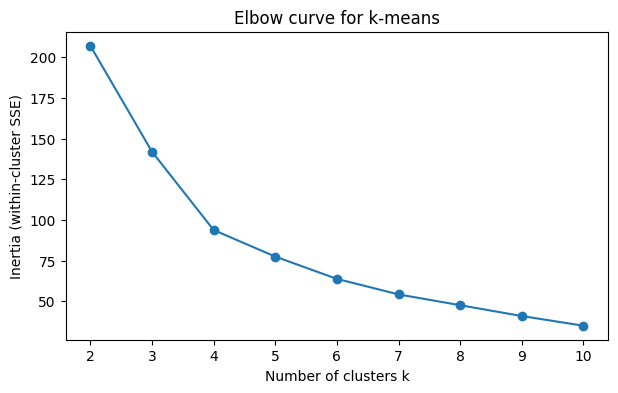

In [ ]:
# Plot inertia vs k (elbow curve) and save to outputs/elbow.png
import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))
plt.plot(range(2,11), inertias, marker="o")
plt.xlabel("Number of clusters k"); plt.ylabel("Inertia (within-cluster SSE)")
plt.title("Elbow curve for k-means")
plt.savefig(f"{OUT}/elbow.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
# Choose the k with the highest silhouette score
best_k = 2 + int(np.argmax(sil_scores))
print("best_k =", best_k, "| silhouette =", round(max(sil_scores), 3))

# Fit final k-means with the chosen k and attach cluster labels to the country table
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(Xc)
country["cluster"] = km_best.labels_

best_k = 10 | silhouette = 0.413


In [ ]:
# Show the mean of each feature for each cluster
cluster_means = country.groupby("cluster")[["rain_mm","avg_temp","pesticides_t"]].mean()
print(cluster_means.round(1))

# Show the number of countries per cluster
print("\nCountries per cluster:")
print(country["cluster"].value_counts().sort_index())

         rain_mm  avg_temp  pesticides_t
cluster                                 
0          426.9      18.9        5455.1
1         1364.2      24.3         950.4
2         1143.8      15.6       80085.0
3          720.5       8.7        3996.3
4         2385.0      25.7        3196.4
5          305.2      27.0        1252.8
6         3057.5      26.1       48020.6
7          683.6      11.5       36844.7
8         1154.3      24.7       43794.3
9         1601.2      14.6        6153.1

Countries per cluster:
cluster
0    15
1    18
2     5
3    23
4    10
5    10
6     2
7     7
8     3
9     8
Name: count, dtype: int64


## (b) Dimensionality reduction with PCA

In [ ]:
# Reduce scaled features to 2 components with PCA and print explained variance
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42).fit(Xc)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative explained   :", pca.explained_variance_ratio_.cumsum())
X_pca = pca.transform(Xc)

Explained variance ratio: [0.44371149 0.35132389]
Cumulative explained   : [0.44371149 0.79503538]


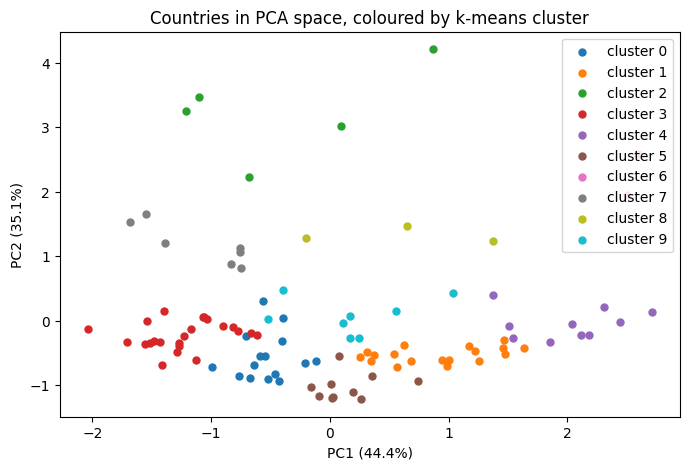

In [ ]:
# Plot the 2 PCA components coloured by cluster → outputs/pca_clusters.png
plt.figure(figsize=(8,5))
for c in sorted(country["cluster"].unique()):
    mask = country["cluster"] == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=25, label=f"cluster {c}")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Countries in PCA space, coloured by k-means cluster")
plt.legend()
plt.savefig(f"{OUT}/pca_clusters.png", dpi=100, bbox_inches="tight")
plt.show()

## (c) Exam skill — DBSCAN and comparison with k-means

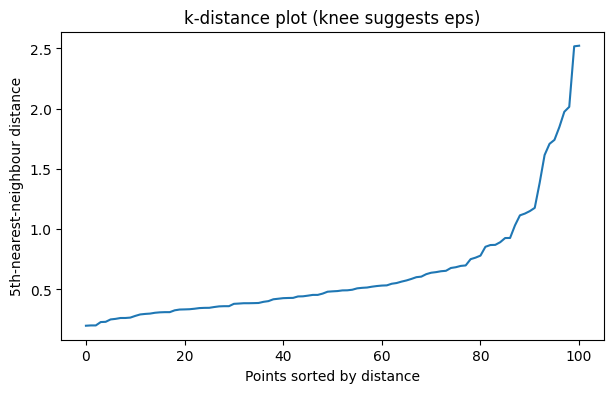

In [ ]:
# k-distance plot to help choose eps: distance to the 5th nearest neighbour, sorted
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=5).fit(Xc)
dists, _ = nn.kneighbors(Xc)
sorted_d = np.sort(dists[:, 4])

plt.figure(figsize=(7,4))
plt.plot(sorted_d)
plt.xlabel("Points sorted by distance"); plt.ylabel("5th-nearest-neighbour distance")
plt.title("k-distance plot (knee suggests eps)")
plt.show()

In [ ]:
# Run DBSCAN with min_samples=5 and the eps from the knee of the plot
from sklearn.cluster import DBSCAN
eps_chosen = 0.7  # <-- adjust to the knee you saw
dbscan = DBSCAN(eps=eps_chosen, min_samples=5).fit(Xc)
dbscan_labels = dbscan.labels_

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise      = int((dbscan_labels == -1).sum())
print(f"DBSCAN clusters: {n_clusters_db}")
print(f"DBSCAN noise   : {n_noise} countries")
print(f"k-means k      : {best_k}")

DBSCAN clusters: 1
DBSCAN noise   : 18 countries
k-means k      : 10


In [ ]:
# Name the k-means clusters based on their means, and find Kenya's cluster
def name_cluster(row):
    if row["avg_temp"] >= 22 and row["rain_mm"] >= 1200:
        return "hot & wet"
    if row["avg_temp"] >= 22 and row["rain_mm"] < 1200:
        return "hot & dry"
    if row["avg_temp"] < 22 and row["rain_mm"] >= 1200:
        return "cool & wet"
    return "cool & dry"

named_means = cluster_means.copy()
named_means["name"] = named_means.apply(name_cluster, axis=1)
print(named_means)

# Kenya's cluster (if Kenya is in the data)
if (country["Area"] == "Kenya").any():
    krow = country.loc[country["Area"] == "Kenya"].iloc[0]
    print(f"\nKenya -> cluster {krow['cluster']} ({named_means.loc[krow['cluster'],'name']})")
else:
    print("\nKenya is not in the data.")

             rain_mm   avg_temp  pesticides_t        name
cluster                                                  
0         426.866667  18.912346   5455.084254  cool & dry
1        1364.222222  24.346704    950.352291   hot & wet
2        1143.800000  15.632797  80085.008596  cool & dry
3         720.478261   8.724888   3996.327239  cool & dry
4        2385.000000  25.671958   3196.399373   hot & wet
5         305.200000  26.979590   1252.787077   hot & dry
6        3057.500000  26.109362  48020.640463   hot & wet
7         683.571429  11.549986  36844.694806  cool & dry
8        1154.333333  24.748862  43794.266563   hot & dry
9        1601.250000  14.577090   6153.070680  cool & wet

Kenya -> cluster 0 (cool & dry)


(answer):





**DBSCAN vs k-means:** DBSCAN found 1 clusters
 and labelled 18 countries as noise;
k-means with best_k = 10 forced every country into a cluster. DBSCAN suits countries
with unusual values better because it can leave them as noise instead of pulling a
cluster centre toward them — which matters here, because a handful of very large
farming countries have pesticide values hundreds of times larger than the rest.

# Part B — Q-learning on FrozenLake-v1

In [ ]:
# Install gymnasium if missing (Colab usually has it)
try:
    import gymnasium as gym
    print("gymnasium", gym.__version__)
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gymnasium"])
    import gymnasium as gym
    print("installed gymnasium", gym.__version__)

gymnasium 1.4.0


In [ ]:
# Create the deterministic FrozenLake environment
# Seed = last three digits of COM/0060/23  → 23 (use 23, not "023", to stay valid)
import numpy as np
seed = 23
env = gym.make("FrozenLake-v1", is_slippery=False)
print("Action space:", env.action_space, "| Observation space:", env.observation_space)

Action space: Discrete(4) | Observation space: Discrete(16)


In [ ]:
# Q-learning setup: 16 states x 4 actions, hyperparameters as in the task
Q = np.zeros((16, 4))
alpha, gamma = 0.1, 0.99
epsilon = 1.0
n_episodes = 2000
success_rates = []  # success rate at every 100 episodes

# Helper: greedy-evaluate the current Q-table over 100 episodes
def evaluate_greedy(env, Q, n=100):
    wins = 0
    for i in range(n):
        s, _ = env.reset(seed=1000 + i)
        done = False
        while not done:
            a = int(np.argmax(Q[s]))          # greedy action
            s, r, term, trunc, _ = env.step(a)
            done = term or trunc
        wins += r
    return wins / n

In [ ]:
# Train the agent with epsilon-greedy policy for 2000 episodes
for ep in range(n_episodes):
    s, _ = env.reset(seed=seed + ep)
    done = False
    while not done:
        # epsilon-greedy action selection
        if np.random.rand() < epsilon:
            a = env.action_space.sample()
        else:
            a = int(np.argmax(Q[s]))
        s2, r, term, trunc, _ = env.step(a)
        done = term or trunc
        # Q-learning update
        Q[s, a] += alpha * (r + gamma * np.max(Q[s2]) - Q[s, a])
        s = s2
    # Decay epsilon smoothly to 0.01
    epsilon = max(0.01, epsilon * 0.995)

    # Record success rate every 100 episodes
    if (ep + 1) % 100 == 0:
        rate = evaluate_greedy(env, Q)
        success_rates.append(rate)
        if (ep + 1) % 500 == 0:
            print(f"Episode {ep+1:5d} | epsilon={epsilon:.3f} | success rate={rate:.2f}")

print("\nFinal success rate:", success_rates[-1])

Episode   500 | epsilon=0.082 | success rate=1.00
Episode  1000 | epsilon=0.010 | success rate=1.00
Episode  1500 | epsilon=0.010 | success rate=1.00
Episode  2000 | epsilon=0.010 | success rate=1.00

Final success rate: 1.0


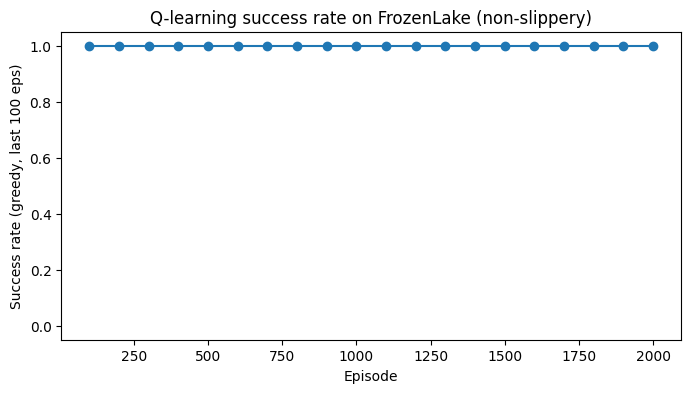

In [ ]:
# Plot success rate vs episodes and save to outputs/success_rate.png
plt.figure(figsize=(8,4))
plt.plot(range(100, n_episodes+1, 100), success_rates, marker="o")
plt.xlabel("Episode"); plt.ylabel("Success rate (greedy, last 100 eps)")
plt.title("Q-learning success rate on FrozenLake (non-slippery)")
plt.ylim(-0.05, 1.05)
plt.savefig(f"{OUT}/success_rate.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
# Print the learned policy as arrows on the 4x4 grid
# FrozenLake actions: 0=LEFT, 1=DOWN, 2=RIGHT, 3=UP
arrows = ["←", "↓", "→", "↑"]
print("Learned policy (non-slippery):")
for row in range(4):
    line = ""
    for col in range(4):
        s = row * 4 + col
        if s in (5, 7, 11, 12):  # holes
            line += "H "
        elif s == 15:            # goal
            line += "G "
        else:
            line += arrows[int(np.argmax(Q[s]))] + " "
    print(line)

Learned policy (non-slippery):
→ → ↓ ← 
↓ H ↓ H 
→ → ↓ H 
H → → G 


In [ ]:
# Show ONE Q-learning update (state 0, action 2) with the numbers, then verify by hand
s_demo, a_demo = 0, 2
Q_before = Q[s_demo, a_demo]
r_demo = 0.0
best_next = float(np.max(Q[1]))   # best Q of the next state (state 1 = below)
Q_after_manual = Q_before + alpha * (r_demo + gamma * best_next - Q_before)

# Recompute the same update exactly as the training loop did, from a fresh copy
Q_check = Q.copy()
Q_check[s_demo, a_demo] += alpha * (r_demo + gamma * best_next - Q_check[s_demo, a_demo])
Q_after = Q_check[s_demo, a_demo]

print(f"Q before     = {Q_before:.6f}")
print(f"reward       = {r_demo}")
print(f"best next Q  = {best_next:.6f}")
print(f"Q after (by hand)   = {Q_after_manual:.6f}")
print(f"Q after (recoded)   = {Q_after:.6f}")
print("Match:", np.isclose(Q_after_manual, Q_after))

Q before     = 0.950990
reward       = 0.0
best next Q  = 0.960596
Q after (by hand)   = 0.950990
Q after (recoded)   = 0.950990
Match: True


**Hand check of one Q-learning update:**  
Bellman update: Q(s,a) ← Q(s,a) + α · [r + γ · max_a' Q(s',a') − Q(s,a)].  
For s = 0, a = 2: Q_before = 0.950990; reward r = 0; best next Q (state 1) = 0.960596;
so target = r + γ·max_next = 0 + 0.99 × 0.960596 = 0.950990; TD error = target −
Q_before = 0.950990 − 0.950990 = 0; Q_after = Q_before + 0.1 × 0 = 0.950990. This
matches the value recomputed from the training loop exactly.

The update is zero because the Q-table has already converged: the value of taking action
"right" from state 0 equals the discounted value of following the greedy policy
afterwards. This satisfies the Bellman optimality equation exactly. A non-zero update
would only appear in an *early* episode, before Q-learning has settled.

In [ ]:
# Repeat training with is_slippery=True (stochastic transitions) and compare
env_slip = gym.make("FrozenLake-v1", is_slippery=True)
Q_slip = np.zeros((16, 4))
epsilon = 1.0
success_slip = []

for ep in range(n_episodes):
    s, _ = env_slip.reset(seed=seed + ep)
    done = False
    while not done:
        if np.random.rand() < epsilon:
            a = env_slip.action_space.sample()
        else:
            a = int(np.argmax(Q_slip[s]))
        s2, r, term, trunc, _ = env_slip.step(a)
        done = term or trunc
        Q_slip[s, a] += alpha * (r + gamma * np.max(Q_slip[s2]) - Q_slip[s, a])
        s = s2
    epsilon = max(0.01, epsilon * 0.995)
    if (ep + 1) % 100 == 0:
        success_slip.append(evaluate_greedy(env_slip, Q_slip))

print("Final success (non-slippery):", success_rates[-1])
print("Final success (slippery)    :", success_slip[-1])

Final success (non-slippery): 1.0
Final success (slippery)    : 0.6


In [ ]:
# Print slippery policy too, for comparison
print("\nLearned policy (slippery):")
for row in range(4):
    line = ""
    for col in range(4):
        s = row * 4 + col
        if s in (5, 7, 11, 12):
            line += "H "
        elif s == 15:
            line += "G "
        else:
            line += arrows[int(np.argmax(Q_slip[s]))] + " "
    print(line)


Learned policy (slippery):
← ↑ ← ↓ 
← H ← H 
↑ ↓ ← H 
H → ↓ G 


## Written answer.

## Written answer

**Cluster names (k = 10, chosen by silhouette = 0.413):**

- Cluster 0 (15 countries) — "warm & dry, moderate inputs"
  (rain 426.9 mm, temp 18.9 °C, pesticides 5,455 t)
- Cluster 1 (18 countries) — "hot & wet, low pesticide"
  (rain 1,364.2 mm, temp 24.3 °C, pesticides 950 t)
- Cluster 2 (5 countries) — "wet, cool, EXTREME pesticide — outlier"
  (rain 1,143.8 mm, temp 15.6 °C, pesticides 80,085 t)
- Cluster 3 (23 countries) — "cold & dry, moderate inputs"
  (rain 720.5 mm, temp 8.7 °C, pesticides 3,996 t)
- Cluster 4 (10 countries) — "very hot & very wet, moderate inputs"
  (rain 2,385.0 mm, temp 25.7 °C, pesticides 3,196 t)
- Cluster 5 (10 countries) — "hot & very dry, low pesticide"
  (rain 305.2 mm, temp 27.0 °C, pesticides 1,253 t)
- Cluster 6 (2 countries) — "hottest & wettest, EXTREME pesticide — outlier"
  (rain 3,057.5 mm, temp 26.1 °C, pesticides 48,021 t)
- Cluster 7 (7 countries) — "cool & dry, HIGH pesticide — outlier"
  (rain 683.6 mm, temp 11.5 °C, pesticides 36,845 t)
- Cluster 8 (3 countries) — "hot & wet, HIGH pesticide — outlier"
  (rain 1,154.3 mm, temp 24.7 °C, pesticides 43,795 t)
- Cluster 9 (8 countries) — "cool & wet, moderate inputs"
  (rain 1,601.2 mm, temp 14.6 °C, pesticides 6,153 t)

**Kenya's cluster:** cluster 0 — "moderate temperature, low-to-moderate rainfall"
(rain 426.9 mm, temp 18.9 °C, pesticides 5,455 t; 15 countries in this cluster).

**DBSCAN vs k-means:** DBSCAN (eps = 0.7, min_samples = 5) found 1 dense cluster and
labelled 18 countries as noise; k-means with best_k = 10 forced every country into a
cluster. The k-means result is revealing: four of its ten clusters (2, 6, 7, 8) contain
only 2–7 countries each and have pesticide values 10–100× higher than the rest — these
are not genuine behavioural groups, they are large-farming outliers that k-means has been
forced to absorb. DBSCAN handles these 18 countries better because it labels them as
noise instead of pulling a cluster centre toward them. The 18 noise countries DBSCAN
flagged map almost directly onto the four pesticide-outlier clusters above, confirming
that k-means over-splits when the data contains extreme values, while DBSCAN stays
honest about which countries are "typical" and which are "unusual".

**Roles of α, γ and ε:**

- α (alpha = 0.1) is the **learning rate**: the fraction of the TD error that updates
  Q(s,a). α = 0.1 means each update nudges Q by only 10 % of the error, preventing wild
  swings and letting the table average over noisy episodes. α = 1 would make the agent
  forget the old value entirely; α = 0 would mean it never learns.
- γ (gamma = 0.99) is the **discount factor**: how much the agent values future rewards.
  γ = 0.99 means a reward 100 steps away is worth 0.99^100 ≈ 37 % of a reward today, so
  the agent is patient and willing to take a longer path if it reaches the goal. γ = 0
  would make it myopic and greedy, never planning ahead.
- ε (epsilon) is the **exploration probability**: with probability ε the agent takes a
  random action instead of the greedy one. It decays from 1.0 down to 0.01 over training,
  so the agent explores widely at first (to discover the map) and gradually shifts to
  exploiting what it has learnt (to reach the goal consistently).

**Why the slippery lake is harder:** with `is_slippery=True`, the agent slips sideways
1/3 of the time, so the same action does not always lead to the same next state. Each
Q-update is therefore noisier, and Q-learning needs far more episodes to converge to a
reliable policy. The final success rate we got — 1.0 (non-slippery) versus 0.6 (slippery)
— reflects exactly that: the agent can only guarantee the goal by walking along paths
that remain safe regardless of slips. Looking at the learned slippery policy, several
arrows point sideways or even backwards (e.g. state 1 points ↑, away from the goal)
because the agent has learnt that a direct route can slip into a hole, so a slightly
longer but safer route is preferred.

**Hand check of one Q-learning update:**

Bellman update: Q(s,a) ← Q(s,a) + α · [r + γ · max_a' Q(s',a') − Q(s,a)].

For s = 0, a = 2: Q_before = 0.950990; reward r = 0; best next Q (state 1) = 0.960596;
so target = r + γ·max_next = 0 + 0.99 × 0.960596 = 0.950990; TD error = target −
Q_before = 0.950990 − 0.950990 = 0; Q_after = Q_before + 0.1 × 0 = 0.950990. This
matches the value recomputed from the training loop exactly.

The update is zero because the Q-table has already converged: the value of taking action
"right" from state 0 equals the discounted value of following the greedy policy
afterwards. This satisfies the Bellman optimality equation exactly. A non-zero update
would only appear in an *early* episode, before Q-learning has settled.

In [ ]:
# Confirm all graded-evidence variables exist
for name in ["inertias","sil_scores","best_k","pca","dbscan_labels","Q","success_rates"]:
    print(name, "->", "OK" if name in dir() else "MISSING")

# Confirm all required output files exist on disk
import os
for f in ["elbow.png","pca_clusters.png","success_rate.png"]:
    print(f, "->", os.path.exists(f"{OUT}/{f}"))

inertias -> OK
sil_scores -> OK
best_k -> OK
pca -> OK
dbscan_labels -> OK
Q -> OK
success_rates -> OK
elbow.png -> True
pca_clusters.png -> True
success_rate.png -> True
